In [2]:
import sys
sys.path.insert(0, "/home/svnssk/GraphRAG")

In [2]:
from graphrag.embeddings.sentence_transformer import SentenceTransformerEmbedder

embedder = SentenceTransformerEmbedder()

vector = embedder.embed("Alice works at Microsoft.")

print(type(vector))
print(vector.shape)
print(vector[:10])

/home/svnssk/GraphRAG/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 770.52it/s]


<class 'numpy.ndarray'>
(384,)
[-0.01669258 -0.02146747 -0.02737217  0.0056963  -0.04187302  0.00787646
  0.0435371  -0.09138682  0.0216442   0.04128189]


In [13]:
texts = [
    "Alice works at Microsoft.",
    "Alice is employed by Microsoft.",
    "The weather is sunny today."
]

vector = embedder.embed(texts)
print(type(vector))
print(vector.shape)
print(vector[:10])

<class 'numpy.ndarray'>
(3, 384)
[[-0.01669263 -0.02146744 -0.02737219 ... -0.04167011  0.04583765
  -0.03098095]
 [-0.01063777 -0.02285189 -0.05152053 ... -0.06353929  0.09528898
  -0.03737053]
 [-0.01396666  0.10453822  0.09329776 ... -0.0118572  -0.1143377
   0.07843284]]


In [14]:
from graphrag.graph.relationship import Relationship
from graphrag.graph.entity import Entity

alice = Entity(id="1", name="Alice", entity_type="Person", description="A software engineer.")
microsoft = Entity(id="2", name="Microsoft", entity_type="Company", description="A technology company.")
relationship = Relationship(id="1", source=alice.id, target=microsoft.id, description="Alice works at Microsoft.")

print(alice)
print(microsoft)
print(relationship)

Entity(id='1', name='Alice', entity_type='Person', description='A software engineer.', metadata={})
Entity(id='2', name='Microsoft', entity_type='Company', description='A technology company.', metadata={})
Relationship(id='1', source='1', target='2', description='Alice works at Microsoft.', weight=1.0, metadata={})


In [15]:
from graphrag.graph.extractor import GraphExtractor

print("GraphExtractor interface OK")

GraphExtractor interface OK


In [18]:
from graphrag.graph.mock_extractor import MockGraphExtractor

extractor = MockGraphExtractor()
entites,relationships = extractor.extract("Alice works at Microsoft.")

print("Entities:")
for entity in entites:
    print(entity)

print("\nRelationships:")
for relationship in relationships:
    print(relationship)

Entities:
Entity(id='entity_001', name='Alice', entity_type='Person', description='A software engineer.', metadata={})
Entity(id='entity_002', name='Microsoft', entity_type='Company', description='A technology company.', metadata={})

Relationships:
Relationship(id='rel_001', source='entity_001', target='entity_002', description='Alice works at Microsoft.', weight=1.0, metadata={})


In [19]:
from graphrag.llm.client import LLM

print("LLM interface OK")

LLM interface OK


In [20]:
from graphrag.llm.mock import MockLLM

llm = MockLLM()

response = llm.generate(
    "Extract entities and relationships from: Alice works at Microsoft."
)

print(response)


        {
            "entities": [
                {
                    "name": "Alice",
                    "type": "PERSON",
                    "description": "A person who works at Microsoft."
                },
                {
                    "name": "Microsoft",
                    "type": "ORGANIZATION",
                    "description": "A technology company."
                }
            ],
            "relationships": [
                {
                    "source": "Alice",
                    "target": "Microsoft",
                    "description": "Alice works at Microsoft."
                }
            ]
        }
        


In [21]:
from graphrag.llm.mock import MockLLM
from graphrag.graph.parser import parse_extraction_response

llm = MockLLM()
response = llm.generate(
    "Extract entities and relationships from: Alice works at Microsoft."
)

entities, relationships = parse_extraction_response(response)

print("Entities:")
for entity in entities:
    print(entity)

print("\nRelationships:")
for relationship in relationships:
    print(relationship)


Entities:
Entity(id='entity_1', name='Alice', entity_type='PERSON', description='A person who works at Microsoft.', metadata={})
Entity(id='entity_2', name='Microsoft', entity_type='ORGANIZATION', description='A technology company.', metadata={})

Relationships:
Relationship(id='rel_1', source='entity_1', target='entity_2', description='Alice works at Microsoft.', weight=1.0, metadata={})


In [24]:
from graphrag.llm.mock import MockLLM
from graphrag.graph.llm_extractor import LLMGraphExtractor

llm = MockLLM()

extractor = LLMGraphExtractor(llm)

text = "Alice works at Microsoft."

entities, relationships = extractor.extract(text)

print("Entities:")
for entity in entities:
    print(entity)

print("\nRelationships:")
for relationship in relationships:
    print(relationship)

Entities:
Entity(id='entity_1', name='Alice', entity_type='PERSON', description='A person who works at Microsoft.', metadata={})
Entity(id='entity_2', name='Microsoft', entity_type='ORGANIZATION', description='A technology company.', metadata={})

Relationships:
Relationship(id='rel_1', source='entity_1', target='entity_2', description='Alice works at Microsoft.', weight=1.0, metadata={})


In [4]:
from graphrag.graph.graph import KnowledgeGraph
from graphrag.graph.entity import Entity
from graphrag.graph.relationship import Relationship


graph = KnowledgeGraph()

alice = Entity(
    id="entity_1",
    name="Alice",
    entity_type="PERSON",
)

microsoft = Entity(
    id="entity_2",
    name="Microsoft",
    entity_type="ORGANIZATION",
)

works_at = Relationship(
    id="rel_1",
    source="entity_1",
    target="entity_2",
    description="Alice works at Microsoft.",
)

graph.add_entity(alice)
graph.add_entity(microsoft)
graph.add_relationship(works_at)

print(graph.entities)
print(graph.relationships)

print(graph.get_entity("entity_1"))
print(graph.get_relationship("rel_1"))

{'entity_1': Entity(id='entity_1', name='Alice', entity_type='PERSON', description='', metadata={}), 'entity_2': Entity(id='entity_2', name='Microsoft', entity_type='ORGANIZATION', description='', metadata={})}
{'rel_1': Relationship(id='rel_1', source='entity_1', target='entity_2', description='Alice works at Microsoft.', weight=1.0, metadata={})}
Entity(id='entity_1', name='Alice', entity_type='PERSON', description='', metadata={})
Relationship(id='rel_1', source='entity_1', target='entity_2', description='Alice works at Microsoft.', weight=1.0, metadata={})


In [1]:
from graphrag.llm.mock import MockLLM
from graphrag.graph.llm_extractor import LLMGraphExtractor
from graphrag.graph.graph import KnowledgeGraph
from graphrag.graph.builder import GraphBuilder

llm = MockLLM()
extractor = LLMGraphExtractor(llm)
builder = GraphBuilder(extractor)
graph = KnowledgeGraph()

builder.add_text(graph,"Alice works at Microsoft.")

print("Entities in the graph:")
for entity in graph.entities.values():
    print(entity)
for relationship in graph.relationships.values():
    print(relationship)

Entities in the graph:
Entity(id='entity_1', name='Alice', entity_type='PERSON', description='A person who works at Microsoft.', metadata={})
Entity(id='entity_2', name='Microsoft', entity_type='ORGANIZATION', description='A technology company.', metadata={})
Relationship(id='rel_1', source='entity_1', target='entity_2', description='Alice works at Microsoft.', weight=1.0, metadata={})


In [25]:
from graphrag.llm.ollama import OllamaLLM
from graphrag.graph.llm_extractor import LLMGraphExtractor
from graphrag.graph.graph import KnowledgeGraph
from graphrag.graph.builder import GraphBuilder
from graphrag.ingestion.document_pipeline import DocumentPipeline


llm = OllamaLLM()
extractor = LLMGraphExtractor(llm)
builder = GraphBuilder(extractor)
pipeline = DocumentPipeline(builder)
graph = KnowledgeGraph()

pipeline.process_file("data/raw/example.txt",graph)

print("Entities in the graph:")
for entity in graph.entities.values():
    print(entity)

print("\nRelationships in the graph:")
for relationship in graph.relationships.values():
    print(relationship)

print("Number of entities:", len(graph.entities))
print("Number of relationships:", len(graph.relationships))


Entities in the graph:
Entity(id='entity_1', name='Alice', entity_type='person', description='software engineer at Microsoft', metadata={})
Entity(id='entity_2', name='Microsoft', entity_type='company', description='develops cloud computing platform Azure', metadata={})
Entity(id='entity_3', name='Azure', entity_type='product', description='cloud computing platform developed by Microsoft', metadata={})
Entity(id='entity_4', name='Bob', entity_type='person', description='data scientist at Google', metadata={})
Entity(id='entity_5', name='Google', entity_type='company', description='develops artificial intelligence model Gemini', metadata={})
Entity(id='entity_6', name='Gemini', entity_type='product', description='artificial intelligence model developed by Google', metadata={})

Relationships in the graph:
Relationship(id='rel_1', source='entity_1', target='entity_2', description='Alice is a software engineer at Microsoft', weight=1.0, metadata={})
Relationship(id='rel_2', source='entity

In [19]:
graph = KnowledgeGraph()
pipeline.process_file("data/raw/example.txt", graph)

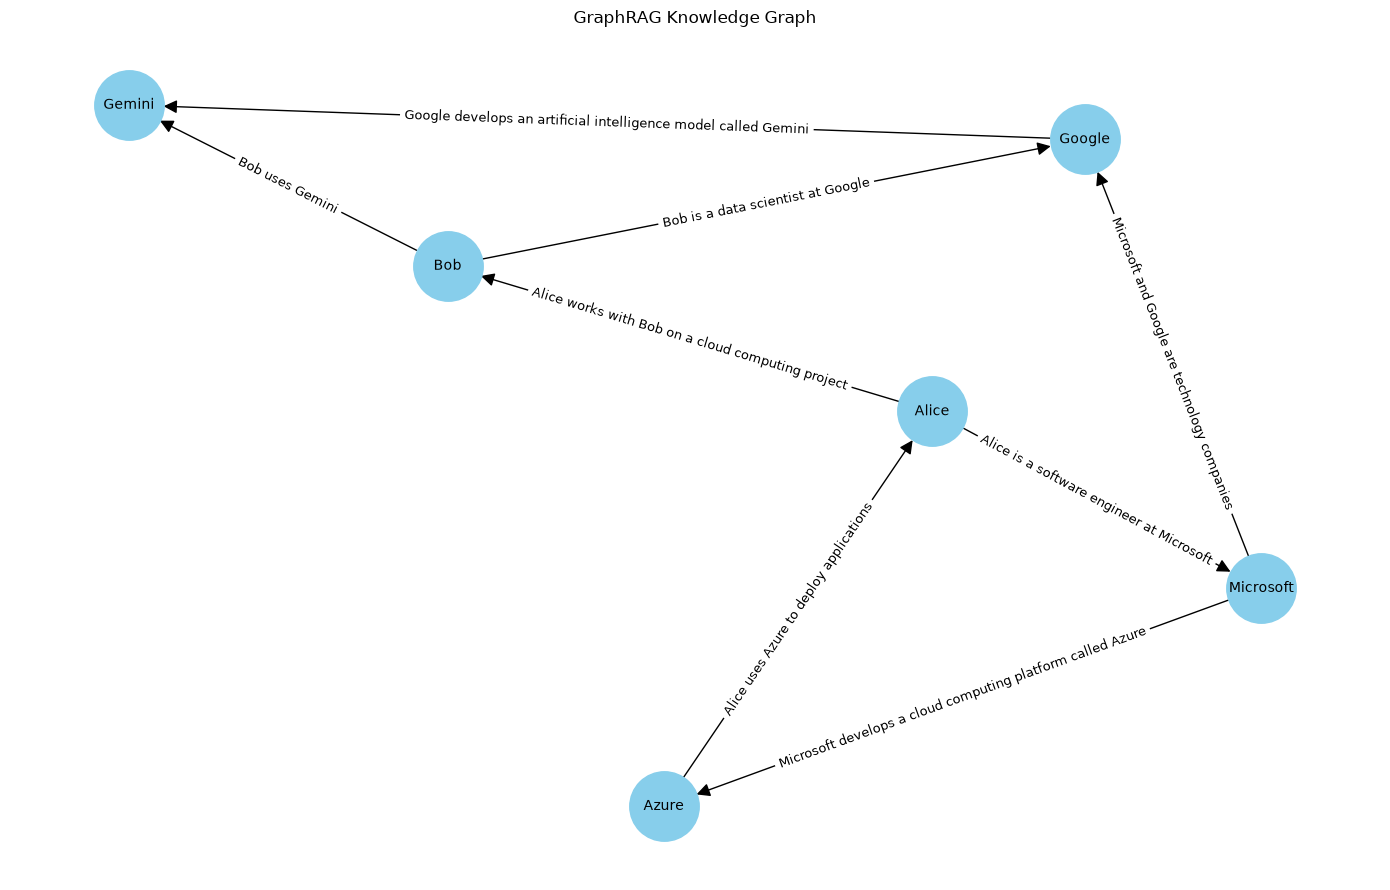

In [26]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()

id_to_name = {
    entity_id: entity.name
    for entity_id, entity in graph.entities.items()
}

for entity_id, entity in graph.entities.items():
    G.add_node(
        entity_id,
        label=entity.name,
        entity_type=entity.entity_type
    )

for rel in graph.relationships.values():
    if rel.source in G and rel.target in G:
        G.add_edge(
            rel.source,
            rel.target,
            label=rel.description
        )

plt.figure(figsize=(14, 9))

pos = nx.spring_layout(G, seed=42, k=1.5)

labels = nx.get_node_attributes(G, "label")

nx.draw_networkx_nodes(
    G, pos,
    node_size=2500,
    node_color="skyblue"
)

nx.draw_networkx_labels(
    G, pos,
    labels=labels,
    font_size=10
)

nx.draw_networkx_edges(
    G, pos,
    arrows=True,
    arrowsize=20,
    node_size=2500
)

edge_labels = nx.get_edge_attributes(G, "label")

nx.draw_networkx_edge_labels(
    G, pos,
    edge_labels=edge_labels,
    font_size=9
)

plt.title("GraphRAG Knowledge Graph")
plt.axis("off")
plt.tight_layout()
plt.show()

In [21]:
import time

start = time.perf_counter()

graph = KnowledgeGraph()
pipeline.process_file("data/raw/example.txt", graph)

end = time.perf_counter()

print(f"Execution time: {end - start:.4f} seconds")
print("Entities:", len(graph.entities))
print("Relationships:", len(graph.relationships))

Execution time: 20.9763 seconds
Entities: 6
Relationships: 9


In [17]:
from pathlib import Path

path = Path("graphrag/graph/parser.py")
print(path.resolve())
print(path.read_text(encoding="utf-8"))

C:\Users\sreek\Sreekar\GraphRAG\GraphRAG\graphrag\graph\parser.py

import json
from graphrag.graph.entity import Entity
from graphrag.graph.relationship import Relationship


def normalize_name(name: str) -> str:
    """Normalize entity names for matching."""
    return " ".join(name.strip().lower().split())


def parse_extraction_response(
    response: str,
) -> tuple[list[Entity], list[Relationship]]:
    data = json.loads(response)

    if not isinstance(data, dict):
        raise ValueError("Extraction response must be a JSON object")

    if "entities" not in data or "relationships" not in data:
        raise ValueError(
            "Extraction response requires entities and relationships"
        )

    entities = []
    relationships = []

    for index, item in enumerate(data["entities"]):
        entities.append(
            Entity(
                id=f"entity_{index + 1}",
                name=item["name"].strip(),
                entity_type=item["type"],
                de